# 777 Radio — First Pipeline (exploratory draft)

**Research question:** Can audio-based ML learn my personal aesthetic tags and reduce manual song annotation?

This is a reproducible first step using the actual CSV. **No acoustic model has been trained yet**, because the archive contains song metadata, not audio files. The existing app’s energy/tempo/valence fields are random placeholders and are not used.

In [1]:
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

df = pd.read_csv("music-dataset.csv")
print("Songs:", len(df))
print("Columns:", list(df.columns))
print("Missing Spotify IDs:", df["spotify_id"].isna().sum())
df.head(3)

Songs: 162
Columns: ['song_id', 'title', 'artist', 'context_tags', 'spotify_id']
Missing Spotify IDs: 160


,song_id,title,artist,context_tags,spotify_id
0,1,Girl Like Me,PinkPantheress,"girlypop, energetic, dance, funky, funny, Y2K,...",NaN
1,2,Televised,HUNNY,"good life, smile, friends, hike, nature, park,...",NaN
2,3,Mis Horas,Los Abuelos de la Nada,"cool, old, vintage, retro, Spanish, Argentina,...",NaN


## Clean the manual tag vocabulary
These labels are targets we eventually want the audio model to predict. We do **not** feed them into an audio model as input features.

In [2]:
def parse_tags(value):
    return [tag.strip().lower() for tag in str(value).split(",") if tag.strip()]

df["tags"] = df["context_tags"].apply(parse_tags)
counts = Counter(tag for tags in df["tags"] for tag in set(tags))
print("Unique tag strings:", len(counts))
print("Most common tags:", counts.most_common(12))

Unique tag strings: 821
Most common tags: [('cool', 28), ('streets', 23), ('night', 17), ('sad', 17), ('cars', 16), ('pink', 15), ('nature', 15), ('love', 15), ('cinematic', 15), ('confident', 14), ('moving', 13), ('aesthetic', 13)]


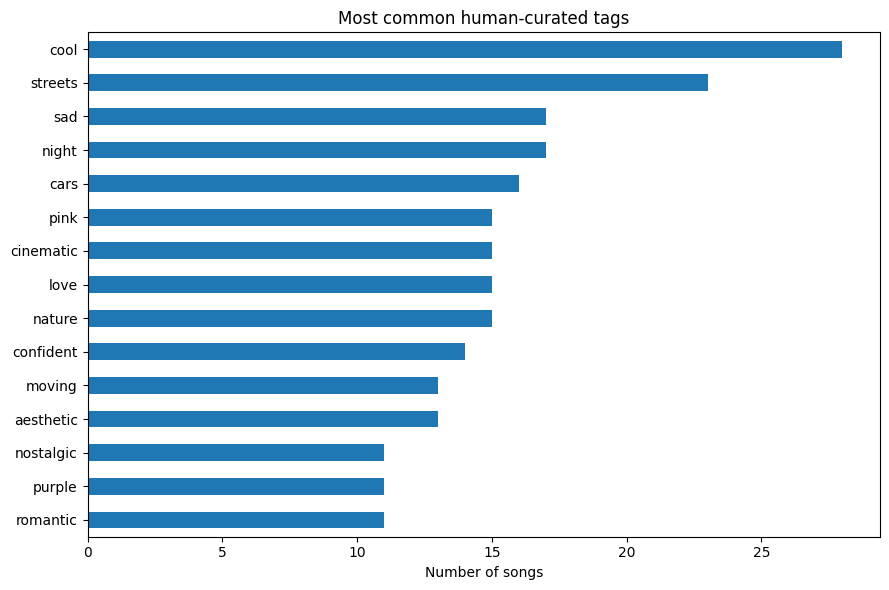

In [3]:
top = pd.Series(dict(counts.most_common(15))).sort_values()
ax = top.plot.barh(figsize=(9, 6), title="Most common human-curated tags")
ax.set_xlabel("Number of songs")
plt.tight_layout()
plt.show()

## Prepare a song-level train/test split
We hold out entire songs. When audio becomes available, acoustic features will be extracted per song and joined by `song_id`. The labels of test songs must not be used during training or hyperparameter selection.

In [4]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, shuffle=True)
print("Train songs:", len(train_df), "Test songs:", len(test_df))
print("No overlapping IDs:", set(train_df.song_id).isdisjoint(set(test_df.song_id)))

Train songs: 129 Test songs: 33
No overlapping IDs: True


## Proposed models (not yet run)

1. **Baseline:** predict frequent tags from the training set.
2. **Logistic regression:** one-vs-rest multi-label classifier on measured audio features.
3. **SVM:** one-vs-rest SVM on the same measured audio features.

Evaluate held-out multi-label precision, recall, F1, and top-k tag retrieval. A secondary experiment will assess whether image-to-song recommendations remain relevant after replacing human tags with predicted tags.

**Blocked dependency:** access to audio recordings that can legally be processed. Song names and Spotify IDs alone do not contain sound.

**Connection to course workbook:** `train_test_split`, logistic regression, SVM, and evaluation/generalization.
